#Improving PlantVillage Model Performance on Real-World Images

## Install Python libraries

In [ ]:
!pip uninstall -y torch torchvision torchaudio transformers datasets accelerate scikit-learn
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
!pip install "transformers>=4.41.0,<6.0.0" datasets accelerate scikit-learn

Found existing installation: torch 2.11.0+cu130
Uninstalling torch-2.11.0+cu130:
  Successfully uninstalled torch-2.11.0+cu130
Found existing installation: torchvision 0.26.0+cu130
Uninstalling torchvision-0.26.0+cu130:
  Successfully uninstalled torchvision-0.26.0+cu130
Found existing installation: torchaudio 2.11.0+cu130
Uninstalling torchaudio-2.11.0+cu130:
  Successfully uninstalled torchaudio-2.11.0+cu130
Found existing installation: transformers 5.18.0
Uninstalling transformers-5.18.0:
  Successfully uninstalled transformers-5.18.0
Found existing installation: datasets 4.8.5
Uninstalling datasets-4.8.5:
  Successfully uninstalled datasets-4.8.5
Found existing installation: accelerate 1.15.0
Uninstalling accelerate-1.15.0:
  Successfully uninstalled accelerate-1.15.0
Found existing installation: scikit-learn 1.6.1
Uninstalling scikit-learn-1.6.1:
  Successfully uninstalled scikit-learn-1.6.1
Looking in indexes: https://download.pytorch.org/whl/cu121
     ━━━━━━━━━━━━━━━━━━━━━━━━━━

##Load Baseline PlantVillage Model

In [ ]:
import torch
from transformers import AutoModelForImageClassification, ViTImageProcessor

MODEL_ID = "mesabo/agri-plant-disease-resnet50"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

processor = ViTImageProcessor.from_pretrained(MODEL_ID)

model = AutoModelForImageClassification.from_pretrained(MODEL_ID)
model = model.to(device)
model.eval()

print("Model loaded!")
print("Number of classes:", model.config.num_labels)

print("\nClasses:")
for idx, label in model.config.id2label.items():
    print(idx, label)

[transformers] `ViTImageProcessor` requires torchvision (not installed); falling back to `ViTImageProcessorPil` for backward compatibility. Install torchvision to use the default backend, or import `ViTImageProcessorPil` directly to silence this warning.


Device: cuda


preprocessor_config.json:   0%|          | 0.00/354 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/3.54k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 94.6MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Model loaded!
Number of classes: 38

Classes:
0 Apple___Apple_scab
1 Apple___Black_rot
2 Apple___Cedar_apple_rust
3 Apple___healthy
4 Blueberry___healthy
5 Cherry_(including_sour)___Powdery_mildew
6 Cherry_(including_sour)___healthy
7 Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 Corn_(maize)___Common_rust_
9 Corn_(maize)___Northern_Leaf_Blight
10 Corn_(maize)___healthy
11 Grape___Black_rot
12 Grape___Esca_(Black_Measles)
13 Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14 Grape___healthy
15 Orange___Haunglongbing_(Citrus_greening)
16 Peach___Bacterial_spot
17 Peach___healthy
18 Pepper,_bell___Bacterial_spot
19 Pepper,_bell___healthy
20 Potato___Early_blight
21 Potato___Late_blight
22 Potato___healthy
23 Raspberry___healthy
24 Soybean___healthy
25 Squash___Powdery_mildew
26 Strawberry___Leaf_scorch
27 Strawberry___healthy
28 Tomato___Bacterial_spot
29 Tomato___Early_blight
30 Tomato___Late_blight
31 Tomato___Leaf_Mold
32 Tomato___Septoria_leaf_spot
33 Tomato___Spider_mites Two-spot

##Load PlantVillage Dataset

In [ ]:
!git clone --depth 1 https://github.com/spMohanty/PlantVillage-Dataset.git

Cloning into 'PlantVillage-Dataset'...
remote: Enumerating objects: 163219, done.
remote: Counting objects: 100% (163219/163219), done.
remote: Compressing objects: 100% (163125/163125), done.
remote: Total 163219 (delta 93), reused 163215 (delta 93), pack-reused 0 (from 0)
Receiving objects: 100% (163219/163219), 2.00 GiB | 18.38 MiB/s, done.
Resolving deltas: 100% (93/93), done.
Updating files: 100% (182404/182404), done.


### Inspect the dataset

In [ ]:
import os

data_dir = "/content/PlantVillage-Dataset/raw/color"

print(os.listdir(data_dir)[:10])

['Apple___healthy', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Late_blight', 'Corn_(maize)___healthy', 'Tomato___Leaf_Mold', 'Apple___Cedar_apple_rust', 'Orange___Haunglongbing_(Citrus_greening)', 'Potato___Late_blight', 'Corn_(maize)___Northern_Leaf_Blight', 'Tomato___Target_Spot']


In [ ]:
classes = sorted([
    d for d in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, d))
])

print("Number of classes:", len(classes))

for i, cls in enumerate(classes):
    print(i, cls)

Number of classes: 38
0 Apple___Apple_scab
1 Apple___Black_rot
2 Apple___Cedar_apple_rust
3 Apple___healthy
4 Blueberry___healthy
5 Cherry_(including_sour)___Powdery_mildew
6 Cherry_(including_sour)___healthy
7 Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 Corn_(maize)___Common_rust_
9 Corn_(maize)___Northern_Leaf_Blight
10 Corn_(maize)___healthy
11 Grape___Black_rot
12 Grape___Esca_(Black_Measles)
13 Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14 Grape___healthy
15 Orange___Haunglongbing_(Citrus_greening)
16 Peach___Bacterial_spot
17 Peach___healthy
18 Pepper,_bell___Bacterial_spot
19 Pepper,_bell___healthy
20 Potato___Early_blight
21 Potato___Late_blight
22 Potato___healthy
23 Raspberry___healthy
24 Soybean___healthy
25 Squash___Powdery_mildew
26 Strawberry___Leaf_scorch
27 Strawberry___healthy
28 Tomato___Bacterial_spot
29 Tomato___Early_blight
30 Tomato___Late_blight
31 Tomato___Leaf_Mold
32 Tomato___Septoria_leaf_spot
33 Tomato___Spider_mites Two-spotted_spider_mite
34 Tomat

## Compare the model's labels with PlantVillage


In [ ]:
## Get the model's labels
model_labels = [
    model.config.id2label[i]
    for i in range(model.config.num_labels)
]

print("Model labels:")
for i, label in enumerate(model_labels):
    print(f"{i:2d}: {label}")

Model labels:
 0: Apple___Apple_scab
 1: Apple___Black_rot
 2: Apple___Cedar_apple_rust
 3: Apple___healthy
 4: Blueberry___healthy
 5: Cherry_(including_sour)___Powdery_mildew
 6: Cherry_(including_sour)___healthy
 7: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
 8: Corn_(maize)___Common_rust_
 9: Corn_(maize)___Northern_Leaf_Blight
10: Corn_(maize)___healthy
11: Grape___Black_rot
12: Grape___Esca_(Black_Measles)
13: Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14: Grape___healthy
15: Orange___Haunglongbing_(Citrus_greening)
16: Peach___Bacterial_spot
17: Peach___healthy
18: Pepper,_bell___Bacterial_spot
19: Pepper,_bell___healthy
20: Potato___Early_blight
21: Potato___Late_blight
22: Potato___healthy
23: Raspberry___healthy
24: Soybean___healthy
25: Squash___Powdery_mildew
26: Strawberry___Leaf_scorch
27: Strawberry___healthy
28: Tomato___Bacterial_spot
29: Tomato___Early_blight
30: Tomato___Late_blight
31: Tomato___Leaf_Mold
32: Tomato___Septoria_leaf_spot
33: Tomato___Spider_mi

In [ ]:
## Get PlantVillage labels
import os

plantvillage_labels = sorted([
    d for d in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, d))
])

print("PlantVillage labels:")
for i, label in enumerate(plantvillage_labels):
    print(f"{i:2d}: {label}")

PlantVillage labels:
 0: Apple___Apple_scab
 1: Apple___Black_rot
 2: Apple___Cedar_apple_rust
 3: Apple___healthy
 4: Blueberry___healthy
 5: Cherry_(including_sour)___Powdery_mildew
 6: Cherry_(including_sour)___healthy
 7: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
 8: Corn_(maize)___Common_rust_
 9: Corn_(maize)___Northern_Leaf_Blight
10: Corn_(maize)___healthy
11: Grape___Black_rot
12: Grape___Esca_(Black_Measles)
13: Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14: Grape___healthy
15: Orange___Haunglongbing_(Citrus_greening)
16: Peach___Bacterial_spot
17: Peach___healthy
18: Pepper,_bell___Bacterial_spot
19: Pepper,_bell___healthy
20: Potato___Early_blight
21: Potato___Late_blight
22: Potato___healthy
23: Raspberry___healthy
24: Soybean___healthy
25: Squash___Powdery_mildew
26: Strawberry___Leaf_scorch
27: Strawberry___healthy
28: Tomato___Bacterial_spot
29: Tomato___Early_blight
30: Tomato___Late_blight
31: Tomato___Leaf_Mold
32: Tomato___Septoria_leaf_spot
33: Tomato___Sp

In [ ]:
model_set = set(model_labels)
plantvillage_set = set(plantvillage_labels)

print("Classes in model but NOT PlantVillage:")
print(model_set - plantvillage_set)

print("\nClasses in PlantVillage but NOT model:")
print(plantvillage_set - model_set)

Classes in model but NOT PlantVillage:
set()

Classes in PlantVillage but NOT model:
set()


In [ ]:
print("Model index → label")
for i, label in enumerate(model_labels):
    print(f"{i:2d}: {label}")

print("\nPlantVillage index → label")
for i, label in enumerate(plantvillage_labels):
    print(f"{i:2d}: {label}")

Model index → label
 0: Apple___Apple_scab
 1: Apple___Black_rot
 2: Apple___Cedar_apple_rust
 3: Apple___healthy
 4: Blueberry___healthy
 5: Cherry_(including_sour)___Powdery_mildew
 6: Cherry_(including_sour)___healthy
 7: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
 8: Corn_(maize)___Common_rust_
 9: Corn_(maize)___Northern_Leaf_Blight
10: Corn_(maize)___healthy
11: Grape___Black_rot
12: Grape___Esca_(Black_Measles)
13: Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14: Grape___healthy
15: Orange___Haunglongbing_(Citrus_greening)
16: Peach___Bacterial_spot
17: Peach___healthy
18: Pepper,_bell___Bacterial_spot
19: Pepper,_bell___healthy
20: Potato___Early_blight
21: Potato___Late_blight
22: Potato___healthy
23: Raspberry___healthy
24: Soybean___healthy
25: Squash___Powdery_mildew
26: Strawberry___Leaf_scorch
27: Strawberry___healthy
28: Tomato___Bacterial_spot
29: Tomato___Early_blight
30: Tomato___Late_blight
31: Tomato___Leaf_Mold
32: Tomato___Septoria_leaf_spot
33: Tomato___Spi

## Create a correct mapping of labels

In [ ]:
model_label_to_idx = {
    label: idx
    for idx, label in enumerate(model_labels)
}

plantvillage_class_to_model_idx = {
    label: model_label_to_idx[label]
    for label in plantvillage_labels
}

In [ ]:
print("Number of PlantVillage classes:", len(plantvillage_class_to_model_idx))

for label, idx in list(plantvillage_class_to_model_idx.items())[:10]:
    print(idx, label)

Number of PlantVillage classes: 38
0 Apple___Apple_scab
1 Apple___Black_rot
2 Apple___Cedar_apple_rust
3 Apple___healthy
4 Blueberry___healthy
5 Cherry_(including_sour)___Powdery_mildew
6 Cherry_(including_sour)___healthy
7 Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 Corn_(maize)___Common_rust_
9 Corn_(maize)___Northern_Leaf_Blight


In [ ]:
## Verify mapping
assert len(model_labels) == 38
assert len(plantvillage_labels) == 38

assert model_set == plantvillage_set

print("✓ Both datasets contain the same 38 classes")
print("✓ Label mapping created successfully")

✓ Both datasets contain the same 38 classes
✓ Label mapping created successfully


## Evaluate Baseline Model Performance on PlantVillage Dataset

In [ ]:
from PIL import Image
from torch.utils.data import Dataset
import os


class PlantVillageDataset(Dataset):

    def __init__(
        self,
        data_dir,
        processor,
        label_mapping,
        transform=None,
        image_paths=None,
        labels=None
    ):
        self.data_dir = data_dir
        self.processor = processor
        self.label_mapping = label_mapping
        self.transform = transform

        # If image paths are provided, use them
        if image_paths is not None and labels is not None:
            self.image_paths = image_paths
            self.labels = labels

        # Otherwise, scan the directory
        else:
            self.image_paths = []
            self.labels = []

            for class_name in os.listdir(data_dir):

                class_path = os.path.join(data_dir, class_name)

                if os.path.isdir(class_path):

                    if class_name not in self.label_mapping:
                        print(
                            f"Warning: {class_name} "
                            "not found in model labels. Skipping."
                        )
                        continue

                    model_idx = self.label_mapping[class_name]

                    for img_name in os.listdir(class_path):

                        img_path = os.path.join(
                            class_path,
                            img_name
                        )

                        if (
                            os.path.isfile(img_path)
                            and img_name.lower().endswith(
                                (".png", ".jpg", ".jpeg")
                            )
                        ):
                            self.image_paths.append(img_path)
                            self.labels.append(model_idx)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        img_path = self.image_paths[idx]
        label = self.labels[idx]

        image = Image.open(img_path).convert("RGB")

        # Apply augmentation only for training
        if self.transform is not None:
            image = self.transform(image)

        inputs = self.processor(
            images=image,
            return_tensors="pt"
        )

        pixel_values = inputs["pixel_values"].squeeze(0)

        return {
            "pixel_values": pixel_values,
            "labels": label
        }

In [ ]:
from sklearn.model_selection import train_test_split

all_image_paths = []
all_labels = []

for class_name in os.listdir(data_dir):

    class_path = os.path.join(data_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    if class_name not in plantvillage_class_to_model_idx:
        continue

    model_idx = plantvillage_class_to_model_idx[class_name]

    for img_name in os.listdir(class_path):

        img_path = os.path.join(class_path, img_name)

        if (
            os.path.isfile(img_path)
            and img_name.lower().endswith(
                (".png", ".jpg", ".jpeg")
            )
        ):
            all_image_paths.append(img_path)
            all_labels.append(model_idx)

In [ ]:
# Create a mapping from PlantVillage class names to model indices
plantvillage_class_to_model_idx = {
    pv_label: model_label_to_idx[pv_label]
    for pv_label in plantvillage_labels
}


from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
import numpy as np

# Your existing dataset
full_dataset = PlantVillageDataset(
    data_dir=data_dir,
    processor=processor,
    label_mapping=plantvillage_class_to_model_idx
)

# Extract labels for stratified splitting.
# Assumes __getitem__ returns (image, label).
labels = np.array(full_dataset.labels)

indices = np.arange(len(full_dataset))

# 80% training, 20% remaining
train_idx, remaining_idx = train_test_split(
    indices,
    test_size=0.20,
    stratify=labels,
    random_state=42
)

# Divide remaining images into validation and test
val_idx, test_idx = train_test_split(
    remaining_idx,
    test_size=0.50,
    stratify=labels[remaining_idx],
    random_state=42
)

print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))

Training: 43444
Validation: 5430
Testing: 5431


In [ ]:
from torch.utils.data import DataLoader, Subset

# Create subsets from the existing full_dataset
# No augmentation is applied

train_dataset = Subset(full_dataset, train_idx)
val_dataset = Subset(full_dataset, val_idx)
test_dataset = Subset(full_dataset, test_idx)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 43444
Validation samples: 5430
Testing samples: 5431


In [ ]:
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate_model(model, dataloader, device):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Evaluating"):
            pixel_values = batch["pixel_values"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(pixel_values)
            logits = outputs.logits
            predictions = torch.argmax(logits, dim=-1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return np.array(all_labels), np.array(all_preds)

# Perform evaluation
true_labels, predictions = evaluate_model(model, test_loader, device)

# Calculate metrics
accuracy = accuracy_score(true_labels, predictions)
precision, recall, f1, _ = precision_recall_fscore_support(
    true_labels, predictions, average='weighted', zero_division=0
)

print(f"\nAccuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

Evaluating:   0%|          | 0/170 [00:00<?, ?it/s]


Accuracy: 0.9589
Precision: 0.9608
Recall: 0.9589
F1-score: 0.9588


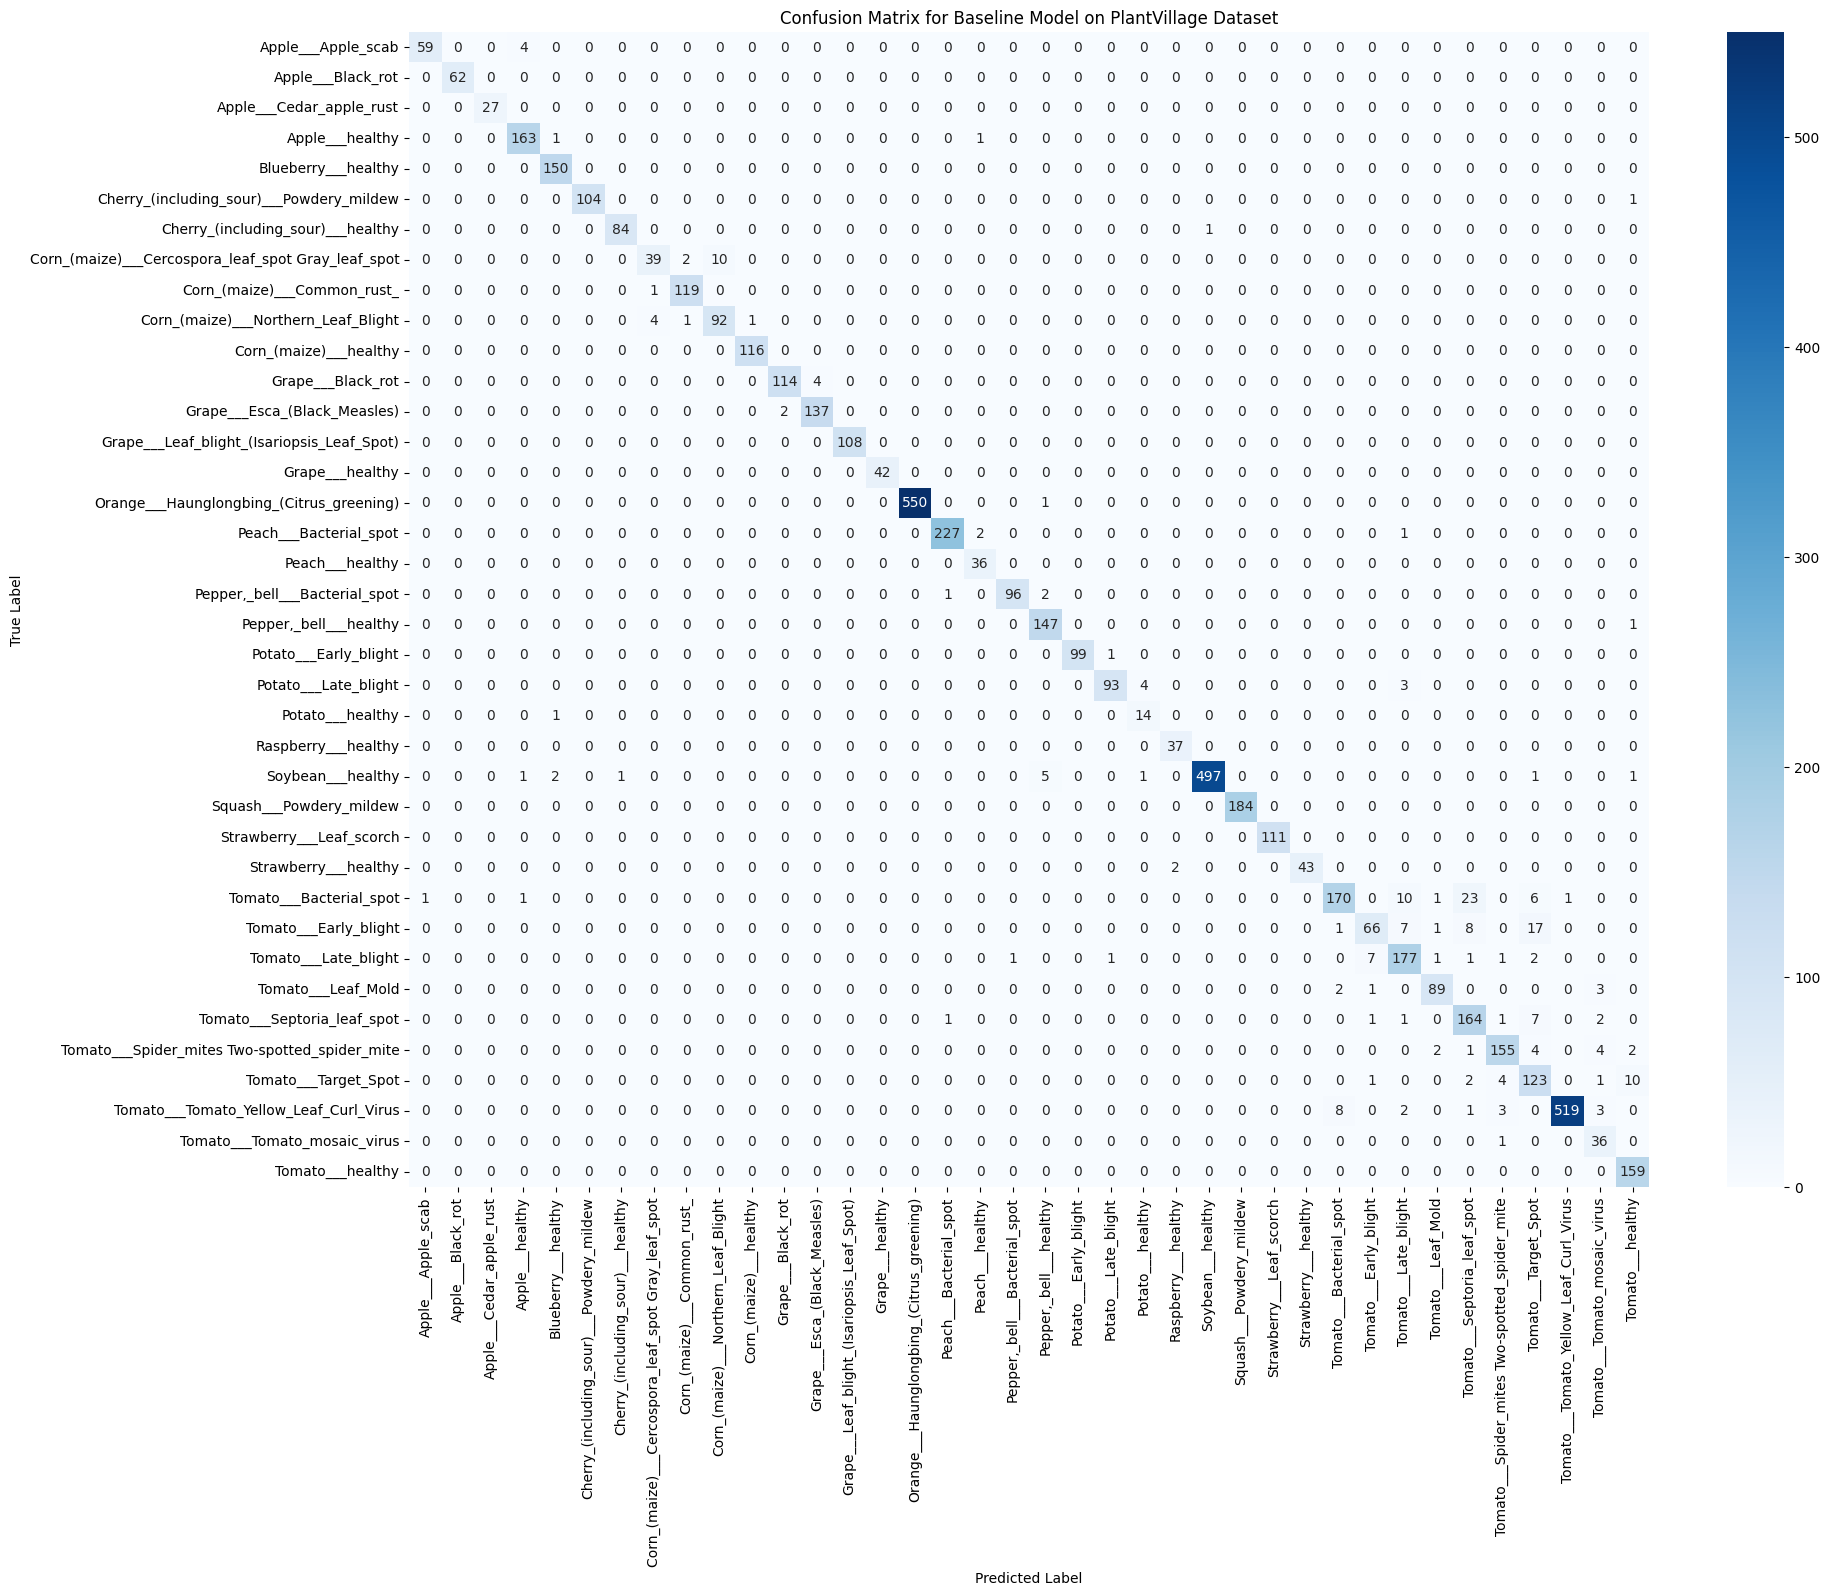

In [ ]:
# Generate Confusion Matrix
cm = confusion_matrix(true_labels, predictions)

plt.figure(figsize=(20, 15))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model_labels,
    yticklabels=model_labels
)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Baseline Model on PlantVillage Dataset')
plt.show()

## Evaluate Model Performance on PlantDoc Dataset

###Load PlantDoc dataset and inspect

In [ ]:
!git clone https://github.com/pratikkayal/PlantDoc-Dataset.git

Cloning into 'PlantDoc-Dataset'...
remote: Enumerating objects: 2670, done.
remote: Counting objects: 100% (35/35), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 2670 (delta 22), reused 22 (delta 22), pack-reused 2635 (from 1)
Receiving objects: 100% (2670/2670), 932.92 MiB | 24.65 MiB/s, done.
Resolving deltas: 100% (24/24), done.
Updating files: 100% (2581/2581), done.


In [ ]:
plantdoc_test_dir = "/content/PlantDoc-Dataset/test"

print(os.listdir(plantdoc_test_dir))


['Strawberry leaf', 'grape leaf', 'Apple leaf', 'Cherry leaf', 'Peach leaf', 'Corn leaf blight', 'grape leaf black rot', 'Tomato leaf yellow virus', 'Bell_pepper leaf', 'Apple Scab Leaf', 'Soyabean leaf', 'Potato leaf late blight', 'Blueberry leaf', 'Tomato Early blight leaf', 'Tomato mold leaf', 'Tomato leaf bacterial spot', 'Tomato Septoria leaf spot', 'Tomato leaf mosaic virus', 'Corn rust leaf', 'Tomato leaf late blight', 'Bell_pepper leaf spot', 'Raspberry leaf', 'Corn Gray leaf spot', 'Squash Powdery mildew leaf', 'Potato leaf early blight', 'Tomato leaf', 'Apple rust leaf']


In [ ]:
from collections import Counter

class_counts = {}

for class_name in os.listdir(plantdoc_test_dir):
    class_path = os.path.join(plantdoc_test_dir, class_name)

    if os.path.isdir(class_path):
        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        class_counts[class_name] = len(images)

class_counts

{'Strawberry leaf': 8,
 'grape leaf': 12,
 'Apple leaf': 9,
 'Cherry leaf': 10,
 'Peach leaf': 9,
 'Corn leaf blight': 12,
 'grape leaf black rot': 8,
 'Tomato leaf yellow virus': 6,
 'Bell_pepper leaf': 8,
 'Apple Scab Leaf': 10,
 'Soyabean leaf': 8,
 'Potato leaf late blight': 8,
 'Blueberry leaf': 11,
 'Tomato Early blight leaf': 9,
 'Tomato mold leaf': 6,
 'Tomato leaf bacterial spot': 9,
 'Tomato Septoria leaf spot': 11,
 'Tomato leaf mosaic virus': 10,
 'Corn rust leaf': 10,
 'Tomato leaf late blight': 10,
 'Bell_pepper leaf spot': 9,
 'Raspberry leaf': 7,
 'Corn Gray leaf spot': 4,
 'Squash Powdery mildew leaf': 6,
 'Potato leaf early blight': 8,
 'Tomato leaf': 8,
 'Apple rust leaf': 10}

###Create PlantDoc dataset

In [ ]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import os


class PlantDocDataset(Dataset):

    def __init__(
        self,
        data_dir,
        processor,
        label_mapping
    ):
        self.data_dir = data_dir
        self.processor = processor
        self.label_mapping = label_mapping

        self.image_paths = []
        self.labels = []

        for class_name in os.listdir(data_dir):

            class_path = os.path.join(
                data_dir,
                class_name
            )

            if not os.path.isdir(class_path):
                continue

            if class_name not in self.label_mapping:
                print(
                    f"Warning: '{class_name}' "
                    "not found in model labels. Skipping."
                )
                continue

            model_idx = self.label_mapping[class_name]

            for img_name in os.listdir(class_path):

                img_path = os.path.join(
                    class_path,
                    img_name
                )

                if (
                    os.path.isfile(img_path)
                    and img_name.lower().endswith(
                        (".png", ".jpg", ".jpeg")
                    )
                ):
                    self.image_paths.append(img_path)
                    self.labels.append(model_idx)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        img_path = self.image_paths[idx]
        label = self.labels[idx]

        image = Image.open(img_path).convert("RGB")

        inputs = self.processor(
        images=image,
        return_tensors="pt",
        do_resize=True,
        size={"height": 224, "width": 224}
        )

        pixel_values = inputs["pixel_values"].squeeze(0)

        # Return a DICTIONARY, matching evaluate_model()
        return {
            "pixel_values": pixel_values,
            "labels": label
        }

###Dataset preprocessing

In [ ]:
!pip install -q torchvision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 72.3 MB/s eta 0:00:00


In [ ]:
plantdoc_to_model_label = {
    "grape leaf": "Grape___healthy",
    "Tomato leaf": "Tomato___healthy",
    "Apple Scab Leaf": "Apple___Apple_scab",
    "Corn Gray leaf spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn leaf blight": "Corn_(maize)___Northern_Leaf_Blight",
    "Cherry leaf": "Cherry_(including_sour)___healthy",
    "Apple leaf": "Apple___healthy",
    "Bell_pepper leaf": "Pepper,_bell___healthy",
    "Raspberry leaf": "Raspberry___healthy",
    "Tomato mold leaf": "Tomato___Leaf_Mold",
    "Tomato leaf late blight": "Tomato___Late_blight",
    "Strawberry leaf": "Strawberry___healthy",
    "Squash Powdery mildew leaf": "Squash___Powdery_mildew",
    "Potato leaf early blight": "Potato___Early_blight",
    "Corn rust leaf": "Corn_(maize)___Common_rust_",
    "Apple rust leaf": "Apple___Cedar_apple_rust",
    "Tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "Tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Blueberry leaf": "Blueberry___healthy",
    "grape leaf black rot": "Grape___Black_rot",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "Soyabean leaf": "Soybean___healthy",
    "Bell_pepper leaf spot": "Pepper,_bell___Bacterial_spot",
    "Peach leaf": "Peach___healthy",
    "Potato leaf late blight": "Potato___Late_blight",
    "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato Septoria leaf spot": "Tomato___Septoria_leaf_spot",
}

plantdoc_class_to_model_idx = {
    plantdoc_class: plantvillage_class_to_model_idx[model_label]
    for plantdoc_class, model_label in plantdoc_to_model_label.items()
}

In [ ]:
for plantdoc_class, model_idx in plantdoc_class_to_model_idx.items():
    model_label = model_labels[model_idx]
    print(f"{plantdoc_class:35} -> {model_label:60} -> {model_idx}")

grape leaf                          -> Grape___healthy                                              -> 14
Tomato leaf                         -> Tomato___healthy                                             -> 37
Apple Scab Leaf                     -> Apple___Apple_scab                                           -> 0
Corn Gray leaf spot                 -> Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot           -> 7
Corn leaf blight                    -> Corn_(maize)___Northern_Leaf_Blight                          -> 9
Cherry leaf                         -> Cherry_(including_sour)___healthy                            -> 6
Apple leaf                          -> Apple___healthy                                              -> 3
Bell_pepper leaf                    -> Pepper,_bell___healthy                                       -> 19
Raspberry leaf                      -> Raspberry___healthy                                          -> 23
Tomato mold leaf                    -> Tomato___Lea

In [ ]:
from torchvision import transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
plantdoc_data_dir = "/content/PlantDoc-Dataset/test"

plantdoc_dataset = PlantDocDataset(
    data_dir=plantdoc_data_dir,
    processor=processor,
    label_mapping=plantdoc_class_to_model_idx
)

plantdoc_loader = DataLoader(
    plantdoc_dataset,
    batch_size=32,
    shuffle=False
)

print("PlantDoc dataset size:", len(plantdoc_dataset))

PlantDoc dataset size: 236


In [ ]:
batch = next(iter(plantdoc_loader))

print(type(batch))
print(batch.keys())
print(batch["pixel_values"].shape)
print(batch["labels"].shape)

<class 'dict'>
dict_keys(['pixel_values', 'labels'])
torch.Size([32, 3, 224, 224])
torch.Size([32])


### Map PlantDoc classes to PlantVillage classes

In [ ]:
# Since 'plantdoc_dataset' doesn't have a 'classes' attribute,
# we can print the classes mapped from our mapping dictionary
for cls in sorted(plantdoc_class_to_model_idx.keys()):
    print(cls)

Apple Scab Leaf
Apple leaf
Apple rust leaf
Bell_pepper leaf
Bell_pepper leaf spot
Blueberry leaf
Cherry leaf
Corn Gray leaf spot
Corn leaf blight
Corn rust leaf
Peach leaf
Potato leaf early blight
Potato leaf late blight
Raspberry leaf
Soyabean leaf
Squash Powdery mildew leaf
Strawberry leaf
Tomato Early blight leaf
Tomato Septoria leaf spot
Tomato leaf
Tomato leaf bacterial spot
Tomato leaf late blight
Tomato leaf mosaic virus
Tomato leaf yellow virus
Tomato mold leaf
grape leaf
grape leaf black rot


In [ ]:
for idx, label in enumerate(model.config.id2label.values()):
    print(idx, label)

0 Apple___Apple_scab
1 Apple___Black_rot
2 Apple___Cedar_apple_rust
3 Apple___healthy
4 Blueberry___healthy
5 Cherry_(including_sour)___Powdery_mildew
6 Cherry_(including_sour)___healthy
7 Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 Corn_(maize)___Common_rust_
9 Corn_(maize)___Northern_Leaf_Blight
10 Corn_(maize)___healthy
11 Grape___Black_rot
12 Grape___Esca_(Black_Measles)
13 Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14 Grape___healthy
15 Orange___Haunglongbing_(Citrus_greening)
16 Peach___Bacterial_spot
17 Peach___healthy
18 Pepper,_bell___Bacterial_spot
19 Pepper,_bell___healthy
20 Potato___Early_blight
21 Potato___Late_blight
22 Potato___healthy
23 Raspberry___healthy
24 Soybean___healthy
25 Squash___Powdery_mildew
26 Strawberry___Leaf_scorch
27 Strawberry___healthy
28 Tomato___Bacterial_spot
29 Tomato___Early_blight
30 Tomato___Late_blight
31 Tomato___Leaf_Mold
32 Tomato___Septoria_leaf_spot
33 Tomato___Spider_mites Two-spotted_spider_mite
34 Tomato___Target_Spot
35 Tom

In [ ]:
plantdoc_to_plantvillage = {
    "Apple Scab Leaf": "Apple___Apple_scab",
    "Apple leaf": "Apple___healthy",
    "Apple rust leaf": "Apple___Cedar_apple_rust",

    "Bell_pepper leaf": "Pepper,_bell___healthy",
    "Bell_pepper leaf spot": "Pepper,_bell___Bacterial_spot",

    "Blueberry leaf": "Blueberry___healthy",

    "Cherry leaf": "Cherry_(including_sour)___healthy",

    "Corn Gray leaf spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn leaf blight": "Corn_(maize)___Northern_Leaf_Blight",
    "Corn rust leaf": "Corn_(maize)___Common_rust_",

    "Peach leaf": "Peach___healthy",

    "Potato leaf early blight": "Potato___Early_blight",
    "Potato leaf late blight": "Potato___Late_blight",

    "Raspberry leaf": "Raspberry___healthy",
    "Soyabean leaf": "Soybean___healthy",

    "Squash Powdery mildew leaf": "Squash___Powdery_mildew",

    "Strawberry leaf": "Strawberry___healthy",

    "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato Septoria leaf spot": "Tomato___Septoria_leaf_spot",
    "Tomato leaf": "Tomato___healthy",
    "Tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "Tomato leaf late blight": "Tomato___Late_blight",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "Tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato mold leaf": "Tomato___Leaf_Mold",

    "grape leaf": "Grape___healthy",
    "grape leaf black rot": "Grape___Black_rot"
}

In [ ]:
plantvillage_to_idx = {
    "Apple___Apple_scab": 0,
    "Apple___Black_rot": 1,
    "Apple___Cedar_apple_rust": 2,
    "Apple___healthy": 3,
    "Blueberry___healthy": 4,
    "Cherry_(including_sour)___Powdery_mildew": 5,
    "Cherry_(including_sour)___healthy": 6,
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot": 7,
    "Corn_(maize)___Common_rust_": 8,
    "Corn_(maize)___Northern_Leaf_Blight": 9,
    "Corn_(maize)___healthy": 10,
    "Grape___Black_rot": 11,
    "Grape___Esca_(Black_Measles)": 12,
    "Grape___Leaf_blight_(Isariopsis_Leaf_Spot)": 13,
    "Grape___healthy": 14,
    "Orange___Haunglongbing_(Citrus_greening)": 15,
    "Peach___Bacterial_spot": 16,
    "Peach___healthy": 17,
    "Pepper,_bell___Bacterial_spot": 18,
    "Pepper,_bell___healthy": 19,
    "Potato___Early_blight": 20,
    "Potato___Late_blight": 21,
    "Potato___healthy": 22,
    "Raspberry___healthy": 23,
    "Soybean___healthy": 24,
    "Squash___Powdery_mildew": 25,
    "Strawberry___Leaf_scorch": 26,
    "Strawberry___healthy": 27,
    "Tomato___Bacterial_spot": 28,
    "Tomato___Early_blight": 29,
    "Tomato___Late_blight": 30,
    "Tomato___Leaf_Mold": 31,
    "Tomato___Septoria_leaf_spot": 32,
    "Tomato___Spider_mites Two-spotted_spider_mite": 33,
    "Tomato___Target_Spot": 34,
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus": 35,
    "Tomato___Tomato_mosaic_virus": 36,
    "Tomato___healthy": 37
}

In [ ]:
plantdoc_to_pv_idx = {
    plantdoc_class: plantvillage_to_idx[pv_class]
    for plantdoc_class, pv_class in plantdoc_to_plantvillage.items()
}

In [ ]:
for plantdoc_class, pv_idx in plantdoc_to_pv_idx.items():
    print(f"{plantdoc_class} -> {pv_idx}")

Apple Scab Leaf -> 0
Apple leaf -> 3
Apple rust leaf -> 2
Bell_pepper leaf -> 19
Bell_pepper leaf spot -> 18
Blueberry leaf -> 4
Cherry leaf -> 6
Corn Gray leaf spot -> 7
Corn leaf blight -> 9
Corn rust leaf -> 8
Peach leaf -> 17
Potato leaf early blight -> 20
Potato leaf late blight -> 21
Raspberry leaf -> 23
Soyabean leaf -> 24
Squash Powdery mildew leaf -> 25
Strawberry leaf -> 27
Tomato Early blight leaf -> 29
Tomato Septoria leaf spot -> 32
Tomato leaf -> 37
Tomato leaf bacterial spot -> 28
Tomato leaf late blight -> 30
Tomato leaf mosaic virus -> 36
Tomato leaf yellow virus -> 35
Tomato mold leaf -> 31
grape leaf -> 14
grape leaf black rot -> 11


In [ ]:
# The custom dataset class doesn't define a '.classes' attribute.
# We can view the mapped classes using our mapping dictionary instead:
print(list(plantdoc_to_pv_idx.keys()))

['Apple Scab Leaf', 'Apple leaf', 'Apple rust leaf', 'Bell_pepper leaf', 'Bell_pepper leaf spot', 'Blueberry leaf', 'Cherry leaf', 'Corn Gray leaf spot', 'Corn leaf blight', 'Corn rust leaf', 'Peach leaf', 'Potato leaf early blight', 'Potato leaf late blight', 'Raspberry leaf', 'Soyabean leaf', 'Squash Powdery mildew leaf', 'Strawberry leaf', 'Tomato Early blight leaf', 'Tomato Septoria leaf spot', 'Tomato leaf', 'Tomato leaf bacterial spot', 'Tomato leaf late blight', 'Tomato leaf mosaic virus', 'Tomato leaf yellow virus', 'Tomato mold leaf', 'grape leaf', 'grape leaf black rot']


### Create the PlantDoc dataset using PlantVillage labels

In [ ]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import os

class PlantDocMappedDataset(Dataset):

    def __init__(self, root_dir, class_mapping, transform=None):
        self.root_dir = root_dir
        self.class_mapping = class_mapping
        self.transform = transform

        self.images = []

        for plantdoc_class in sorted(os.listdir(root_dir)):

            class_dir = os.path.join(root_dir, plantdoc_class)

            if not os.path.isdir(class_dir):
                continue

            # Skip classes that don't have a mapping
            if plantdoc_class not in class_mapping:
                print(f"Skipping unmapped class: {plantdoc_class}")
                continue

            plantvillage_label = class_mapping[plantdoc_class]

            for filename in os.listdir(class_dir):

                if filename.lower().endswith((".jpg", ".jpeg", ".png")):

                    image_path = os.path.join(class_dir, filename)

                    self.images.append(
                        (image_path, plantvillage_label)
                    )

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        image_path, label = self.images[idx]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

### Create the PlantDoc test dataset

In [ ]:
plantdoc_dataset = PlantDocMappedDataset(
    root_dir=plantdoc_test_dir,
    class_mapping=plantdoc_to_pv_idx,
    transform=transform
)

print("Number of PlantDoc images:", len(plantdoc_dataset))

Number of PlantDoc images: 236


In [ ]:
plantdoc_loader = DataLoader(
    plantdoc_dataset,
    batch_size=32,
    shuffle=False
)

In [ ]:
print(model.config.id2label)

{0: 'Apple___Apple_scab', 1: 'Apple___Black_rot', 2: 'Apple___Cedar_apple_rust', 3: 'Apple___healthy', 4: 'Blueberry___healthy', 5: 'Cherry_(including_sour)___Powdery_mildew', 6: 'Cherry_(including_sour)___healthy', 7: 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 8: 'Corn_(maize)___Common_rust_', 9: 'Corn_(maize)___Northern_Leaf_Blight', 10: 'Corn_(maize)___healthy', 11: 'Grape___Black_rot', 12: 'Grape___Esca_(Black_Measles)', 13: 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 14: 'Grape___healthy', 15: 'Orange___Haunglongbing_(Citrus_greening)', 16: 'Peach___Bacterial_spot', 17: 'Peach___healthy', 18: 'Pepper,_bell___Bacterial_spot', 19: 'Pepper,_bell___healthy', 20: 'Potato___Early_blight', 21: 'Potato___Late_blight', 22: 'Potato___healthy', 23: 'Raspberry___healthy', 24: 'Soybean___healthy', 25: 'Squash___Powdery_mildew', 26: 'Strawberry___Leaf_scorch', 27: 'Strawberry___healthy', 28: 'Tomato___Bacterial_spot', 29: 'Tomato___Early_blight', 30: 'Tomato___Late_blight', 31: 'To

### Generate predictions

In [ ]:
all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in plantdoc_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = torch.argmax(
            outputs.logits,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

In [ ]:
print("Number of predictions:", len(all_predictions))
print("Number of labels:", len(all_labels))

Number of predictions: 236
Number of labels: 236


### Calculate the metrics

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

Accuracy:  0.2754
Precision: 0.2579
Recall:    0.2147
F1-score:  0.2020


###Generate the confusion matrix

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# PlantVillage labels represented in PlantDoc
used_labels = sorted(set(all_labels))

# Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=used_labels
)

# Corresponding PlantVillage class names
target_names = [
    plantvillage_labels[label]
    for label in used_labels
]

print("Number of classes:", len(used_labels))
print("Number of labels:", len(target_names))

Number of classes: 27
Number of labels: 27


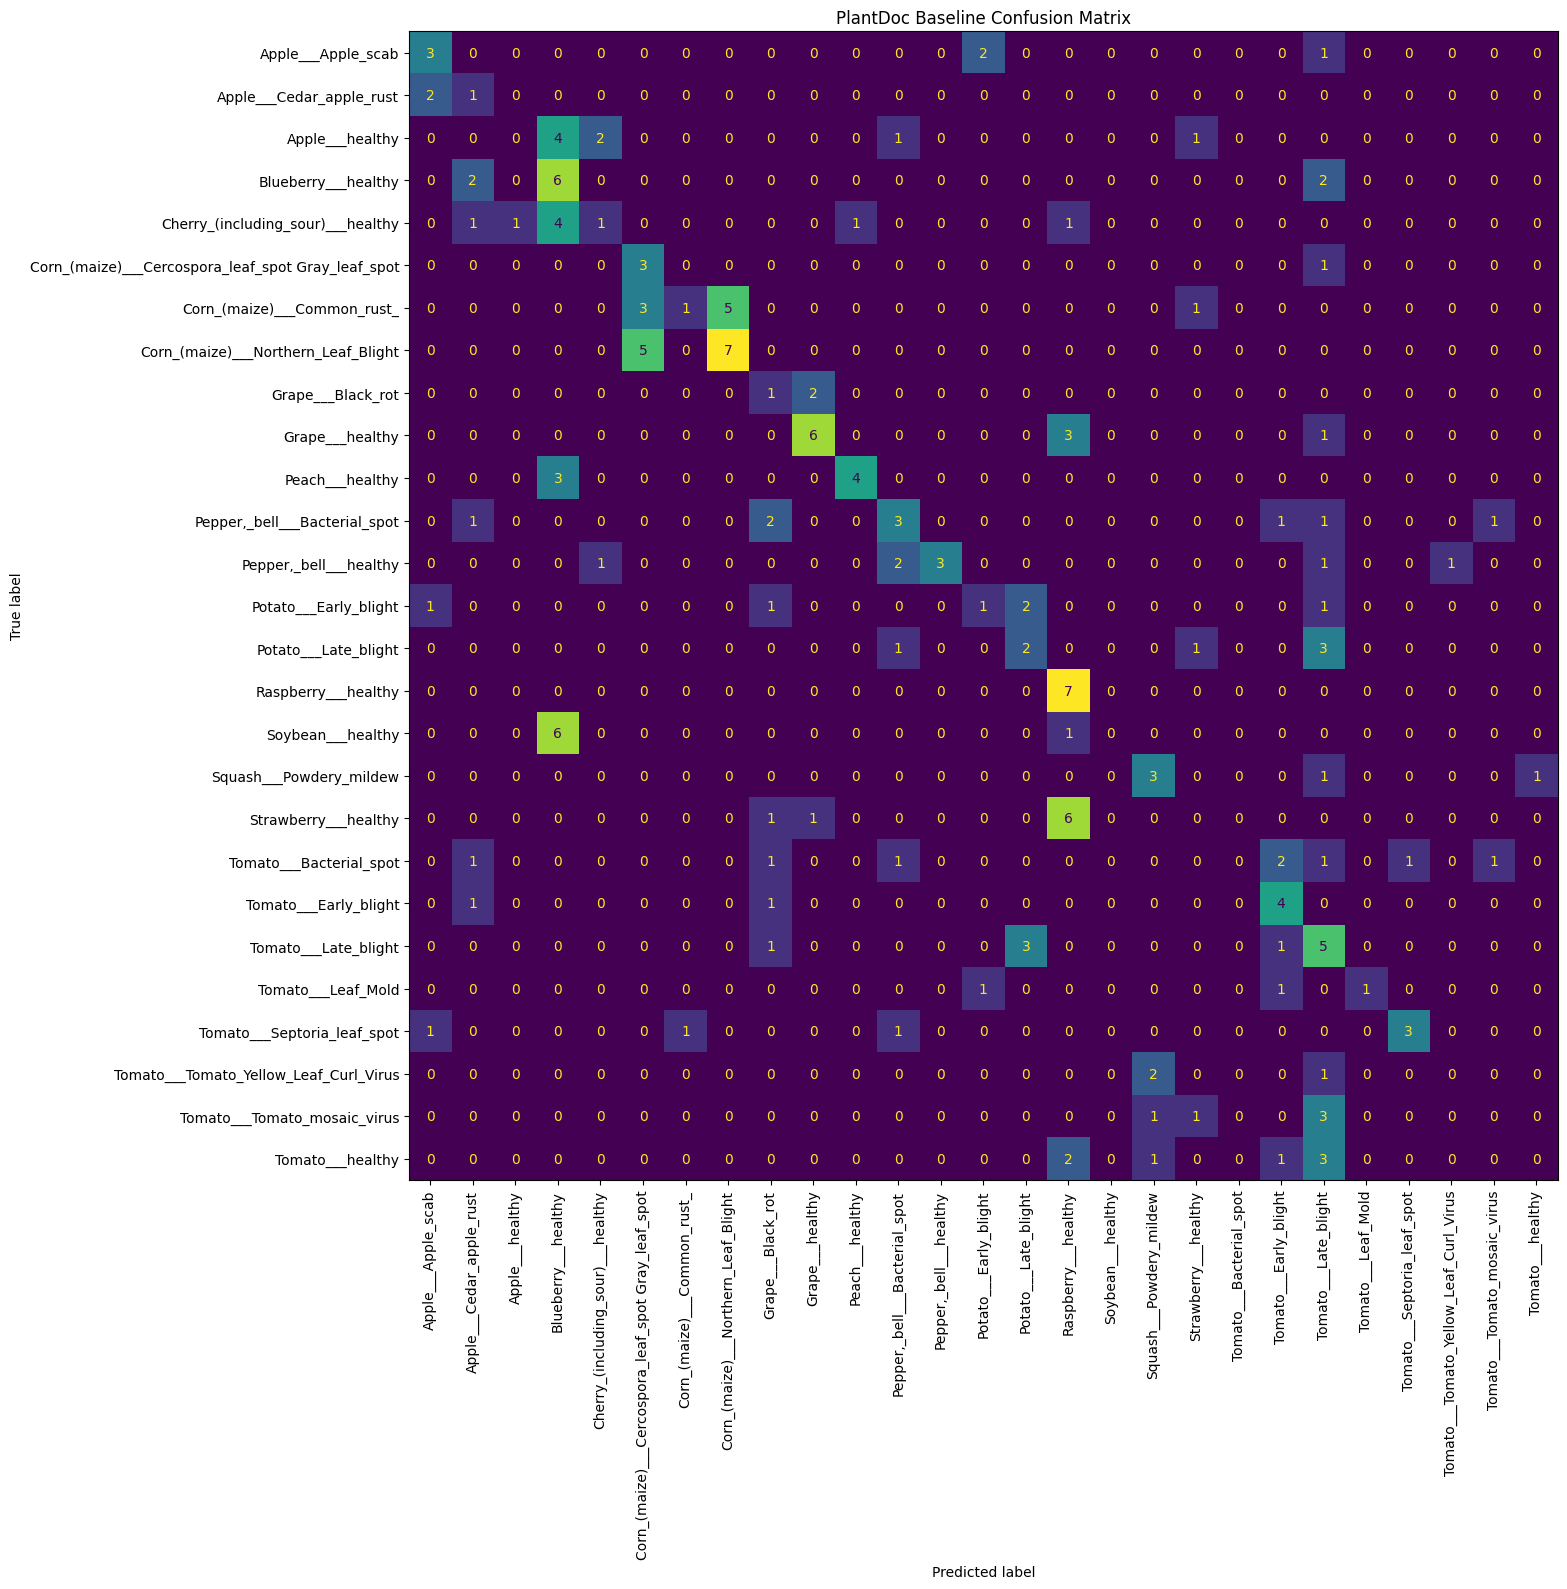

In [ ]:
fig, ax = plt.subplots(figsize=(16, 16))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_names
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=False
)

plt.title("PlantDoc Baseline Confusion Matrix")
plt.tight_layout()
plt.show()

###Inspect and analyse the results

In [ ]:
from sklearn.metrics import classification_report

report = classification_report(
    all_labels,
    all_predictions,
    labels=used_labels,
    target_names=target_names,
    zero_division=0
)

print(report)

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.43      0.30      0.35        10
                          Apple___Cedar_apple_rust       0.14      0.10      0.12        10
                                   Apple___healthy       0.00      0.00      0.00         9
                               Blueberry___healthy       0.26      0.55      0.35        11
                 Cherry_(including_sour)___healthy       0.25      0.10      0.14        10
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.27      0.75      0.40         4
                       Corn_(maize)___Common_rust_       0.50      0.10      0.17        10
               Corn_(maize)___Northern_Leaf_Blight       0.58      0.58      0.58        12
                                 Grape___Black_rot       0.12      0.12      0.12         8
                                   Grape___healthy       0.67      0.50      0.

In [ ]:
## Find the best and worst-performing classes
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(
    all_labels,
    all_predictions,
    labels=used_labels,
    zero_division=0
)

class_results = pd.DataFrame({
    "Class": target_names,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Support": support
})

class_results = class_results.sort_values(
    "F1-score",
    ascending=False
)

class_results

,Class,Precision,Recall,F1-score,Support
7,Corn_(maize)___Northern_Leaf_Blight,0.583333,0.583333,0.583333,12
9,Grape___healthy,0.666667,0.500000,0.571429,12
10,Peach___healthy,0.800000,0.444444,0.571429,9
12,"Pepper,_bell___healthy",1.000000,0.375000,0.545455,8
15,Raspberry___healthy,0.350000,1.000000,0.518519,7
17,Squash___Powdery_mildew,0.428571,0.500000,0.461538,6
20,Tomato___Early_blight,0.400000,0.444444,0.421053,9
5,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,0.272727,0.750000,0.400000,4
23,Tomato___Septoria_leaf_spot,0.750000,0.272727,0.400000,11
0,Apple___Apple_scab,0.428571,0.300000,0.352941,10


In [ ]:
## Lowest F1-scores
class_results.sort_values("F1-score").head(10)

,Class,Precision,Recall,F1-score,Support
2,Apple___healthy,0.000000,0.000,0.000000,9
24,Tomato___Tomato_Yellow_Leaf_Curl_Virus,0.000000,0.000,0.000000,6
26,Tomato___healthy,0.000000,0.000,0.000000,8
25,Tomato___Tomato_mosaic_virus,0.000000,0.000,0.000000,10
16,Soybean___healthy,0.000000,0.000,0.000000,8
18,Strawberry___healthy,0.000000,0.000,0.000000,8
19,Tomato___Bacterial_spot,0.000000,0.000,0.000000,9
1,Apple___Cedar_apple_rust,0.142857,0.100,0.117647,10
8,Grape___Black_rot,0.125000,0.125,0.125000,8
4,Cherry_(including_sour)___healthy,0.250000,0.100,0.142857,10


In [ ]:
# Highest F1-scores
class_results.sort_values("F1-score", ascending=False).head(10)

,Class,Precision,Recall,F1-score,Support
7,Corn_(maize)___Northern_Leaf_Blight,0.583333,0.583333,0.583333,12
9,Grape___healthy,0.666667,0.500000,0.571429,12
10,Peach___healthy,0.800000,0.444444,0.571429,9
12,"Pepper,_bell___healthy",1.000000,0.375000,0.545455,8
15,Raspberry___healthy,0.350000,1.000000,0.518519,7
17,Squash___Powdery_mildew,0.428571,0.500000,0.461538,6
20,Tomato___Early_blight,0.400000,0.444444,0.421053,9
5,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,0.272727,0.750000,0.400000,4
23,Tomato___Septoria_leaf_spot,0.750000,0.272727,0.400000,11
0,Apple___Apple_scab,0.428571,0.300000,0.352941,10


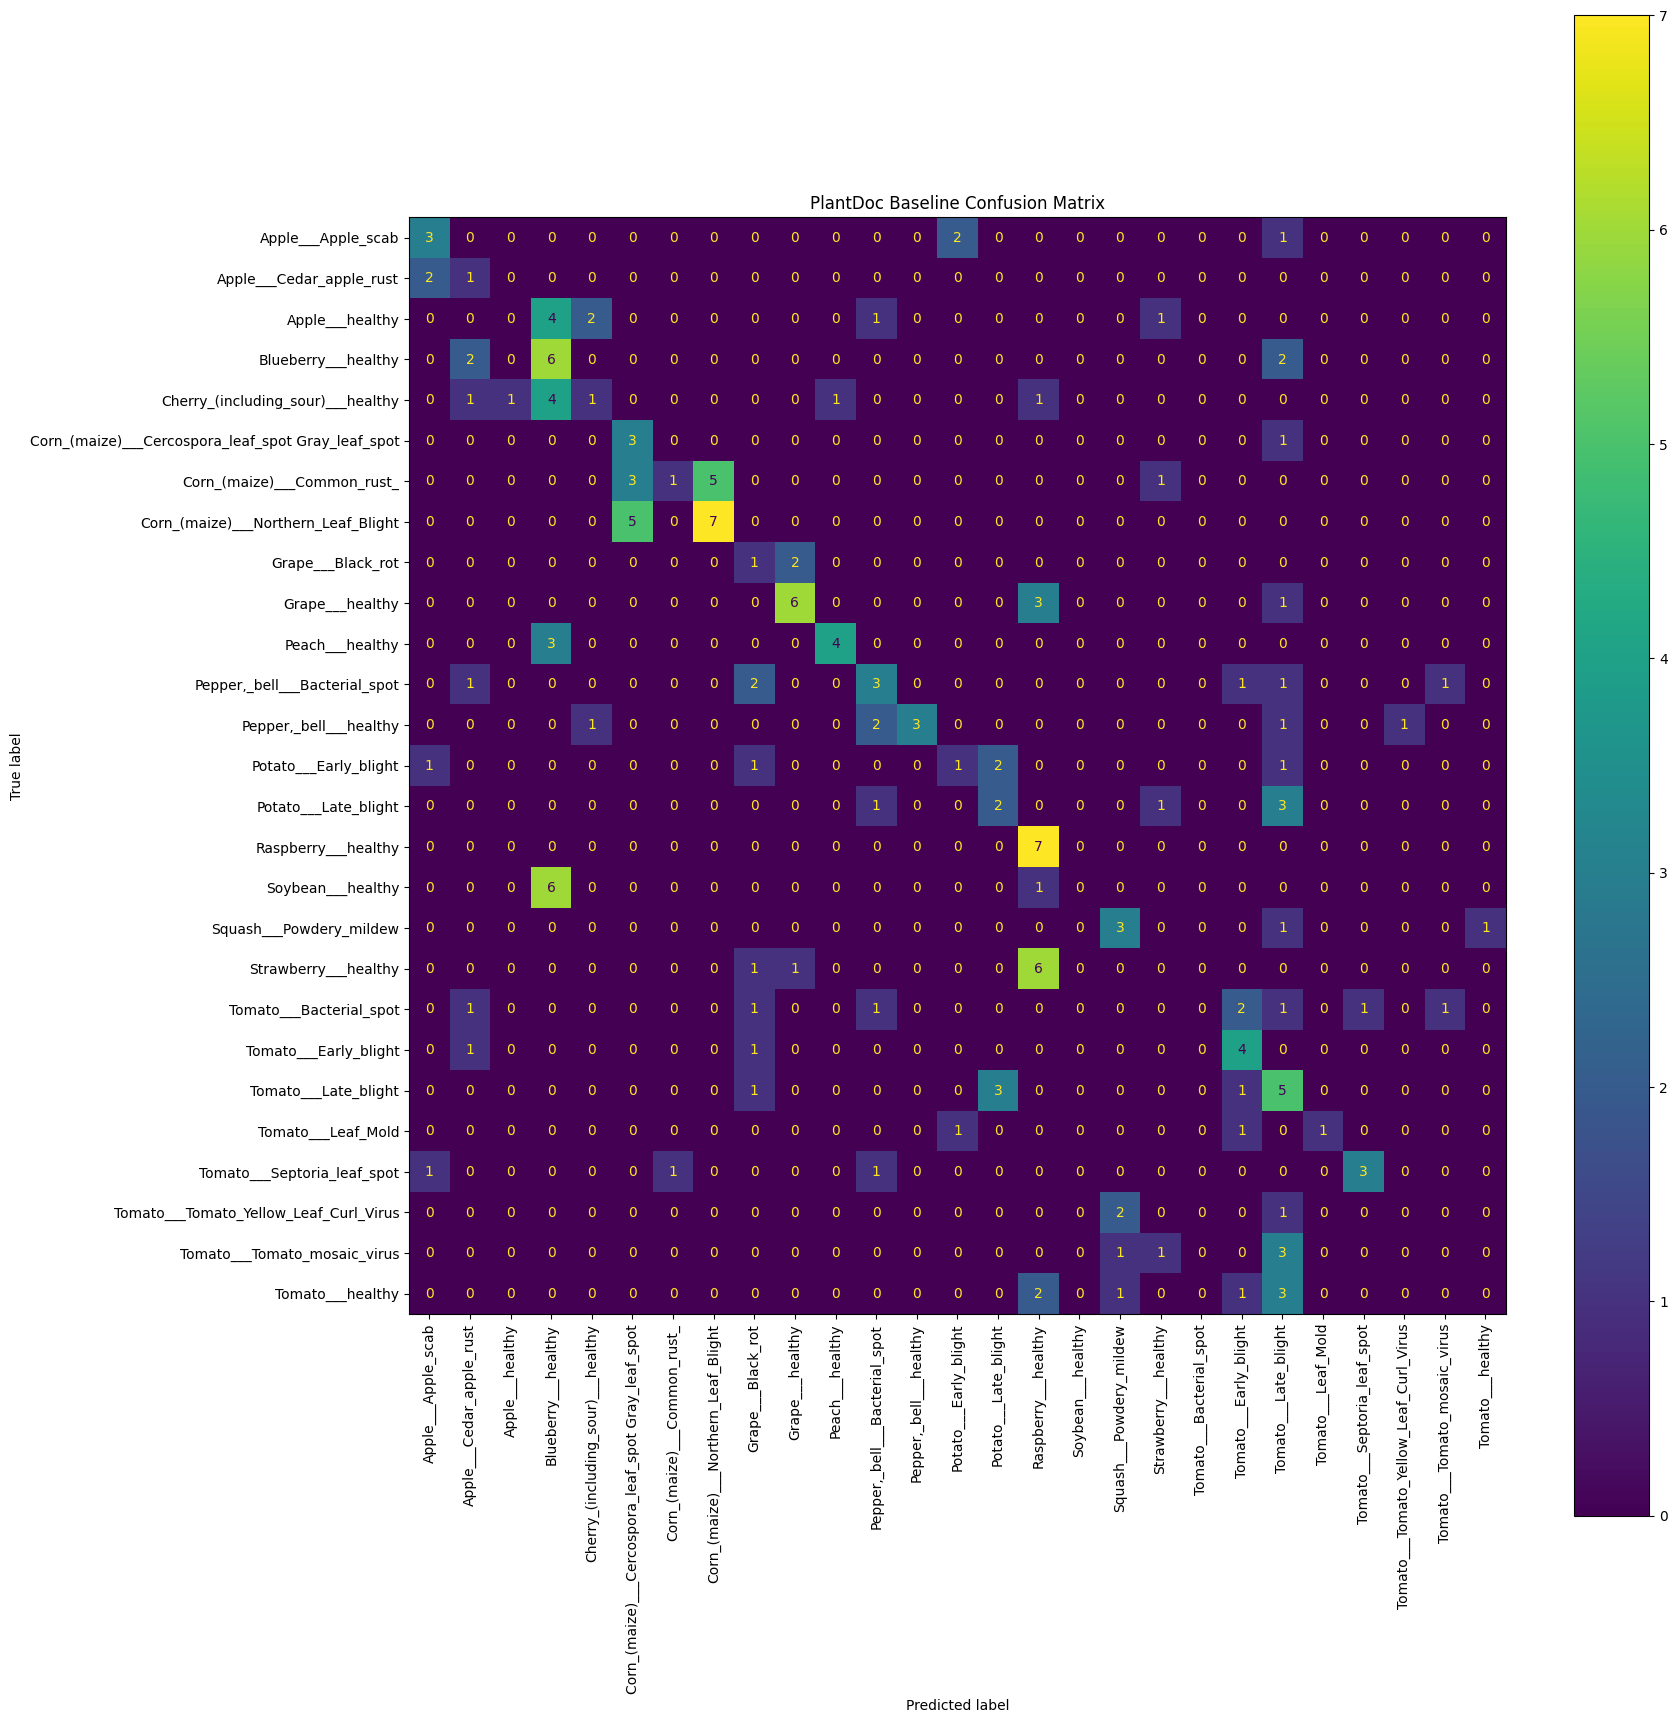

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(18, 18))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=target_names
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=True
)

plt.title("PlantDoc Baseline Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

confusions = []

for i, actual_label in enumerate(used_labels):
    for j, predicted_label in enumerate(used_labels):

        if i != j and cm[i, j] > 0:

            confusions.append({
                "Actual": plantvillage_labels[actual_label],
                "Predicted": plantvillage_labels[predicted_label],
                "Count": cm[i, j]
            })

confusions_df = pd.DataFrame(confusions)

confusions_df = confusions_df.sort_values(
    "Count",
    ascending=False
)

confusions_df.head(10)

,Actual,Predicted,Count
45,Strawberry___healthy,Raspberry___healthy,6
39,Soybean___healthy,Blueberry___healthy,6
18,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,5
16,Corn_(maize)___Common_rust_,Corn_(maize)___Northern_Leaf_Blight,5
3,Apple___healthy,Blueberry___healthy,4
11,Cherry_(including_sour)___healthy,Blueberry___healthy,4
20,Grape___healthy,Raspberry___healthy,3
38,Potato___Late_blight,Tomato___Late_blight,3
56,Tomato___Late_blight,Potato___Late_blight,3
67,Tomato___Tomato_mosaic_virus,Tomato___Late_blight,3


In [ ]:
print(processor)

ViTImageProcessorPil {
  "crop_pct": 0.875,
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.485,
    0.456,
    0.406
  ],
  "image_processor_type": "ViTImageProcessor",
  "image_std": [
    0.229,
    0.224,
    0.225
  ],
  "resample": 3,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "shortest_edge": 224
  }
}



## Apply Data Augmentation Techniques to PlantVillage Training Set

### Modify PlantVillage DatasetClass

In [ ]:
from PIL import Image
from torch.utils.data import Dataset
import os


class PlantVillageDataset(Dataset):

    def __init__(
        self,
        data_dir,
        processor,
        label_mapping,
        transform=None,
        image_paths=None,
        labels=None
    ):
        self.data_dir = data_dir
        self.processor = processor
        self.label_mapping = label_mapping
        self.transform = transform

        # If specific image paths and labels are provided,
        # use those instead of scanning the entire directory.
        if image_paths is not None and labels is not None:

            self.image_paths = image_paths
            self.labels = labels

        else:

            self.image_paths = []
            self.labels = []

            for class_name in os.listdir(data_dir):

                class_path = os.path.join(data_dir, class_name)

                if os.path.isdir(class_path):

                    try:
                        model_idx = self.label_mapping[class_name]

                    except KeyError:
                        print(
                            f"Warning: Class '{class_name}' "
                            "found in dataset but not in model labels. "
                            "Skipping."
                        )
                        continue

                    for img_name in os.listdir(class_path):

                        img_path = os.path.join(
                            class_path,
                            img_name
                        )

                        if (
                            os.path.isfile(img_path)
                            and img_name.lower().endswith(
                                ('.png', '.jpg', '.jpeg')
                            )
                        ):
                            self.image_paths.append(img_path)
                            self.labels.append(model_idx)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        img_path = self.image_paths[idx]
        label = self.labels[idx]

        image = Image.open(img_path).convert("RGB")

        # Apply augmentation only if a transform was supplied.
        # Training dataset → augmentation
        # Test dataset → no augmentation
        if self.transform is not None:
            image = self.transform(image)

        # Apply Hugging Face preprocessing
        inputs = self.processor(
            images=image,
            return_tensors="pt"
        )

        pixel_values = inputs["pixel_values"].squeeze(0)

        return {
            "pixel_values": pixel_values,
            "labels": label
        }

### Define Training Augmentation

In [ ]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        size=224,
        scale=(0.8, 1.0)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=15
    ),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    )
])

### Redefine splits

In [ ]:
from sklearn.model_selection import train_test_split

all_image_paths = []
all_labels = []

for class_name in os.listdir(data_dir):

    class_path = os.path.join(data_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    if class_name not in plantvillage_class_to_model_idx:
        continue

    model_idx = plantvillage_class_to_model_idx[class_name]

    for img_name in os.listdir(class_path):

        img_path = os.path.join(class_path, img_name)

        if (
            os.path.isfile(img_path)
            and img_name.lower().endswith(
                (".png", ".jpg", ".jpeg")
            )
        ):
            all_image_paths.append(img_path)
            all_labels.append(model_idx)

In [ ]:
train_paths, test_paths, train_labels, test_labels = train_test_split(
    all_image_paths,
    all_labels,
    test_size=0.2,
    random_state=42,
    stratify=all_labels
)

### Create the datasets



In [ ]:
train_dataset = PlantVillageDataset(
    data_dir=data_dir,
    processor=processor,
    label_mapping=plantvillage_class_to_model_idx,
    transform=train_transform,
    image_paths=train_paths,
    labels=train_labels
)

test_dataset = PlantVillageDataset(
    data_dir=data_dir,
    processor=processor,
    label_mapping=plantvillage_class_to_model_idx,
    transform=None,
    image_paths=test_paths,
    labels=test_labels
)

from torch.utils.data import DataLoader

train_dataloader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_dataloader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

## Fine-tune the pretrained model to the augmented dataset

### Load the pretrained model and move it to GPU

In [ ]:
# import torch

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# model = AutoModelForImageClassification.from_pretrained(MODEL_ID)
# model.to(device)

# print("Device:", device)

### Set up the optimizer

In [ ]:
from torch.optim import AdamW

optimizer = AdamW(
    model.parameters(),
    lr=1e-5,
    weight_decay=0.01
)

### Training loop

In [ ]:
from tqdm.auto import tqdm

num_epochs = 5

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0

    progress_bar = tqdm(
        train_dataloader,
        desc=f"Epoch {epoch + 1}/{num_epochs}"
    )

    for batch in progress_bar:

        pixel_values = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(
            pixel_values=pixel_values,
            labels=labels
        )

        loss = outputs.loss

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item()

        progress_bar.set_postfix(
            loss=loss.item()
        )

    avg_loss = running_loss / len(train_dataloader)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Average training loss: {avg_loss:.4f}"
    )

Epoch 1/5:   0%|          | 0/1358 [00:00<?, ?it/s]

Epoch 1/5 - Average training loss: 0.2663


Epoch 2/5:   0%|          | 0/1358 [00:00<?, ?it/s]

Epoch 2/5 - Average training loss: 0.1886


Epoch 3/5:   0%|          | 0/1358 [00:00<?, ?it/s]

Epoch 3/5 - Average training loss: 0.1545


Epoch 4/5:   0%|          | 0/1358 [00:00<?, ?it/s]

Epoch 4/5 - Average training loss: 0.1409


Epoch 5/5:   0%|          | 0/1358 [00:00<?, ?it/s]

Epoch 5/5 - Average training loss: 0.1235


## Add validation after every epoch

In [ ]:
from tqdm.auto import tqdm

num_epochs = 5

for epoch in range(num_epochs):

    # =========================
    # Training
    # =========================

    model.train()

    running_loss = 0.0

    progress_bar = tqdm(
        train_dataloader,
        desc=f"Training Epoch {epoch + 1}/{num_epochs}"
    )

    for batch in progress_bar:

        pixel_values = batch["pixel_values"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(
            pixel_values=pixel_values,
            labels=labels
        )

        loss = outputs.loss

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    avg_train_loss = running_loss / len(train_dataloader)

    # =========================
    # Validation
    # =========================

    model.eval()

    correct = 0
    total = 0
    validation_loss = 0.0

    with torch.no_grad():

        for batch in test_dataloader:

            pixel_values = batch["pixel_values"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                pixel_values=pixel_values,
                labels=labels
            )

            validation_loss += outputs.loss.item()

            predictions = torch.argmax(
                outputs.logits,
                dim=-1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    avg_validation_loss = (
        validation_loss / len(test_dataloader)
    )

    validation_accuracy = correct / total

    print(
        f"\nEpoch {epoch + 1}/{num_epochs}"
    )

    print(
        f"Training loss:   {avg_train_loss:.4f}"
    )

    print(
        f"Validation loss: {avg_validation_loss:.4f}"
    )

    print(
        f"Validation acc:  {validation_accuracy:.4f}"
    )

    print("-" * 50)

Training Epoch 1/5:   0%|          | 0/1358 [00:00<?, ?it/s]


Epoch 1/5
Training loss:   0.1083
Validation loss: 0.0574
Validation acc:  0.9822
--------------------------------------------------


Training Epoch 2/5:   0%|          | 0/1358 [00:00<?, ?it/s]


Epoch 2/5
Training loss:   0.0978
Validation loss: 0.0532
Validation acc:  0.9834
--------------------------------------------------


Training Epoch 3/5:   0%|          | 0/1358 [00:00<?, ?it/s]


Epoch 3/5
Training loss:   0.0907
Validation loss: 0.0498
Validation acc:  0.9830
--------------------------------------------------


Training Epoch 4/5:   0%|          | 0/1358 [00:00<?, ?it/s]


Epoch 4/5
Training loss:   0.0813
Validation loss: 0.0462
Validation acc:  0.9855
--------------------------------------------------


Training Epoch 5/5:   0%|          | 0/1358 [00:00<?, ?it/s]


Epoch 5/5
Training loss:   0.0760
Validation loss: 0.0408
Validation acc:  0.9865
--------------------------------------------------


##Save the fine-tuned model

In [ ]:
output_dir = "/content/plantvillage_resnet50_augmented"

model.save_pretrained(output_dir)
processor.save_pretrained(output_dir)

print(f"Model saved to: {output_dir}")

# reloading the model
# model = AutoModelForImageClassification.from_pretrained(
#     output_dir
# )

# processor = ViTImageProcessor.from_pretrained(
#     output_dir
# )

# model.to(device)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: /content/plantvillage_resnet50_augmented


## Evaluate Fine-Tuned Model Performance on PlantDoc

In [ ]:
def evaluate_model_tuples(model, dataloader, device):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in tqdm(dataloader, desc="Evaluating"):
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            logits = outputs.logits
            predictions = torch.argmax(logits, dim=-1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return np.array(all_labels), np.array(all_preds)

true_labels, predictions = evaluate_model_tuples(
    model,
    plantdoc_loader,
    device
)

Evaluating:   0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:
accuracy = accuracy_score(
    true_labels,
    predictions
)

precision, recall, f1, _ = precision_recall_fscore_support(
    true_labels,
    predictions,
    average="weighted",
    zero_division=0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

Accuracy:  0.2500
Precision: 0.3764
Recall:    0.2500
F1-score:  0.2572


## Evaluate Fine-Tuned Model Performance on PlantVillage Dataset

In [ ]:
model = AutoModelForImageClassification.from_pretrained(
    output_dir
)

processor = ViTImageProcessor.from_pretrained(
    output_dir
)

model.to(device)

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

ResNetForImageClassification(
  (resnet): ResNetModel(
    (embedder): ResNetEmbeddings(
      (embedder): ResNetConvLayer(
        (convolution): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
        (normalization): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (activation): ReLU()
      )
      (pooler): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    )
    (encoder): ResNetEncoder(
      (stages): ModuleList(
        (0): ResNetStage(
          (layers): Sequential(
            (0): ResNetBottleNeckLayer(
              (shortcut): ResNetShortCut(
                (convolution): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
                (normalization): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
              )
              (layer): Sequential(
                (0): ResNetConvLayer(
                  (c

In [ ]:
from PIL import Image
from torch.utils.data import Dataset
import os


class PlantVillageDataset(Dataset):

    def __init__(
        self,
        data_dir,
        processor,
        label_mapping,
        transform=None,
        image_paths=None,
        labels=None
    ):
        self.data_dir = data_dir
        self.processor = processor
        self.label_mapping = label_mapping
        self.transform = transform

        # If image paths are provided, use them
        if image_paths is not None and labels is not None:
            self.image_paths = image_paths
            self.labels = labels

        # Otherwise, scan the directory
        else:
            self.image_paths = []
            self.labels = []

            for class_name in os.listdir(data_dir):

                class_path = os.path.join(data_dir, class_name)

                if os.path.isdir(class_path):

                    if class_name not in self.label_mapping:
                        print(
                            f"Warning: {class_name} "
                            "not found in model labels. Skipping."
                        )
                        continue

                    model_idx = self.label_mapping[class_name]

                    for img_name in os.listdir(class_path):

                        img_path = os.path.join(
                            class_path,
                            img_name
                        )

                        if (
                            os.path.isfile(img_path)
                            and img_name.lower().endswith(
                                (".png", ".jpg", ".jpeg")
                            )
                        ):
                            self.image_paths.append(img_path)
                            self.labels.append(model_idx)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        img_path = self.image_paths[idx]
        label = self.labels[idx]

        image = Image.open(img_path).convert("RGB")

        # Apply augmentation only for training
        if self.transform is not None:
            image = self.transform(image)

        inputs = self.processor(
            images=image,
            return_tensors="pt"
        )

        pixel_values = inputs["pixel_values"].squeeze(0)

        return {
            "pixel_values": pixel_values,
            "labels": label
        }

In [ ]:
from sklearn.model_selection import train_test_split

all_image_paths = []
all_labels = []

for class_name in os.listdir(data_dir):

    class_path = os.path.join(data_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    if class_name not in plantvillage_class_to_model_idx:
        continue

    model_idx = plantvillage_class_to_model_idx[class_name]

    for img_name in os.listdir(class_path):

        img_path = os.path.join(class_path, img_name)

        if (
            os.path.isfile(img_path)
            and img_name.lower().endswith(
                (".png", ".jpg", ".jpeg")
            )
        ):
            all_image_paths.append(img_path)
            all_labels.append(model_idx)

In [ ]:
# Create a mapping from PlantVillage class names to model indices
plantvillage_class_to_model_idx = {
    pv_label: model_label_to_idx[pv_label]
    for pv_label in plantvillage_labels
}

# Instantiate the dataset
eval_dataset = PlantVillageDataset(
    data_dir=data_dir,
    processor=processor,
    label_mapping=plantvillage_class_to_model_idx
)

# Create a DataLoader
eval_dataloader = DataLoader(eval_dataset, batch_size=32, shuffle=False)

print(f"Number of images in evaluation dataset: {len(eval_dataset)}")

Number of images in evaluation dataset: 54305


In [ ]:
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate_model(model, dataloader, device):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Evaluating"):
            pixel_values = batch["pixel_values"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(pixel_values)
            logits = outputs.logits
            predictions = torch.argmax(logits, dim=-1)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return np.array(all_labels), np.array(all_preds)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

# Evaluate the fine-tuned model on the baseline 10% test split
true_labels, strict_predictions = evaluate_model(model, strict_test_loader, device)

# Calculate metrics
accuracy = accuracy_score(strict_true_labels, strict_predictions)
precision, recall, f1, _ = precision_recall_fscore_support(
    strict_true_labels, strict_predictions, average='weighted', zero_division=0
)

print(f"\n--- Model Performance Comparison (10% Test Split) ---")
print(f"Baseline Model Accuracy:   0.9589")
print(f"Baseline Model F1-score:   0.9588")
print(f"-----------------------------------------------")
print(f"Fine-Tuned Model Accuracy:  {accuracy:.4f}")
print(f"Fine-Tuned Model Precision: {precision:.4f}")
print(f"Fine-Tuned Model Recall:    {recall:.4f}")
print(f"Fine-Tuned Model F1-score:  {f1:.4f}")

Evaluating:   0%|          | 0/340 [00:00<?, ?it/s]


--- Model Performance Comparison (10% Test Split) ---
Baseline Model Accuracy:   0.9589
Baseline Model F1-score:   0.9588
-----------------------------------------------
Fine-Tuned Model Accuracy:  0.9865
Fine-Tuned Model Precision: 0.9866
Fine-Tuned Model Recall:    0.9865
Fine-Tuned Model F1-score:  0.9864


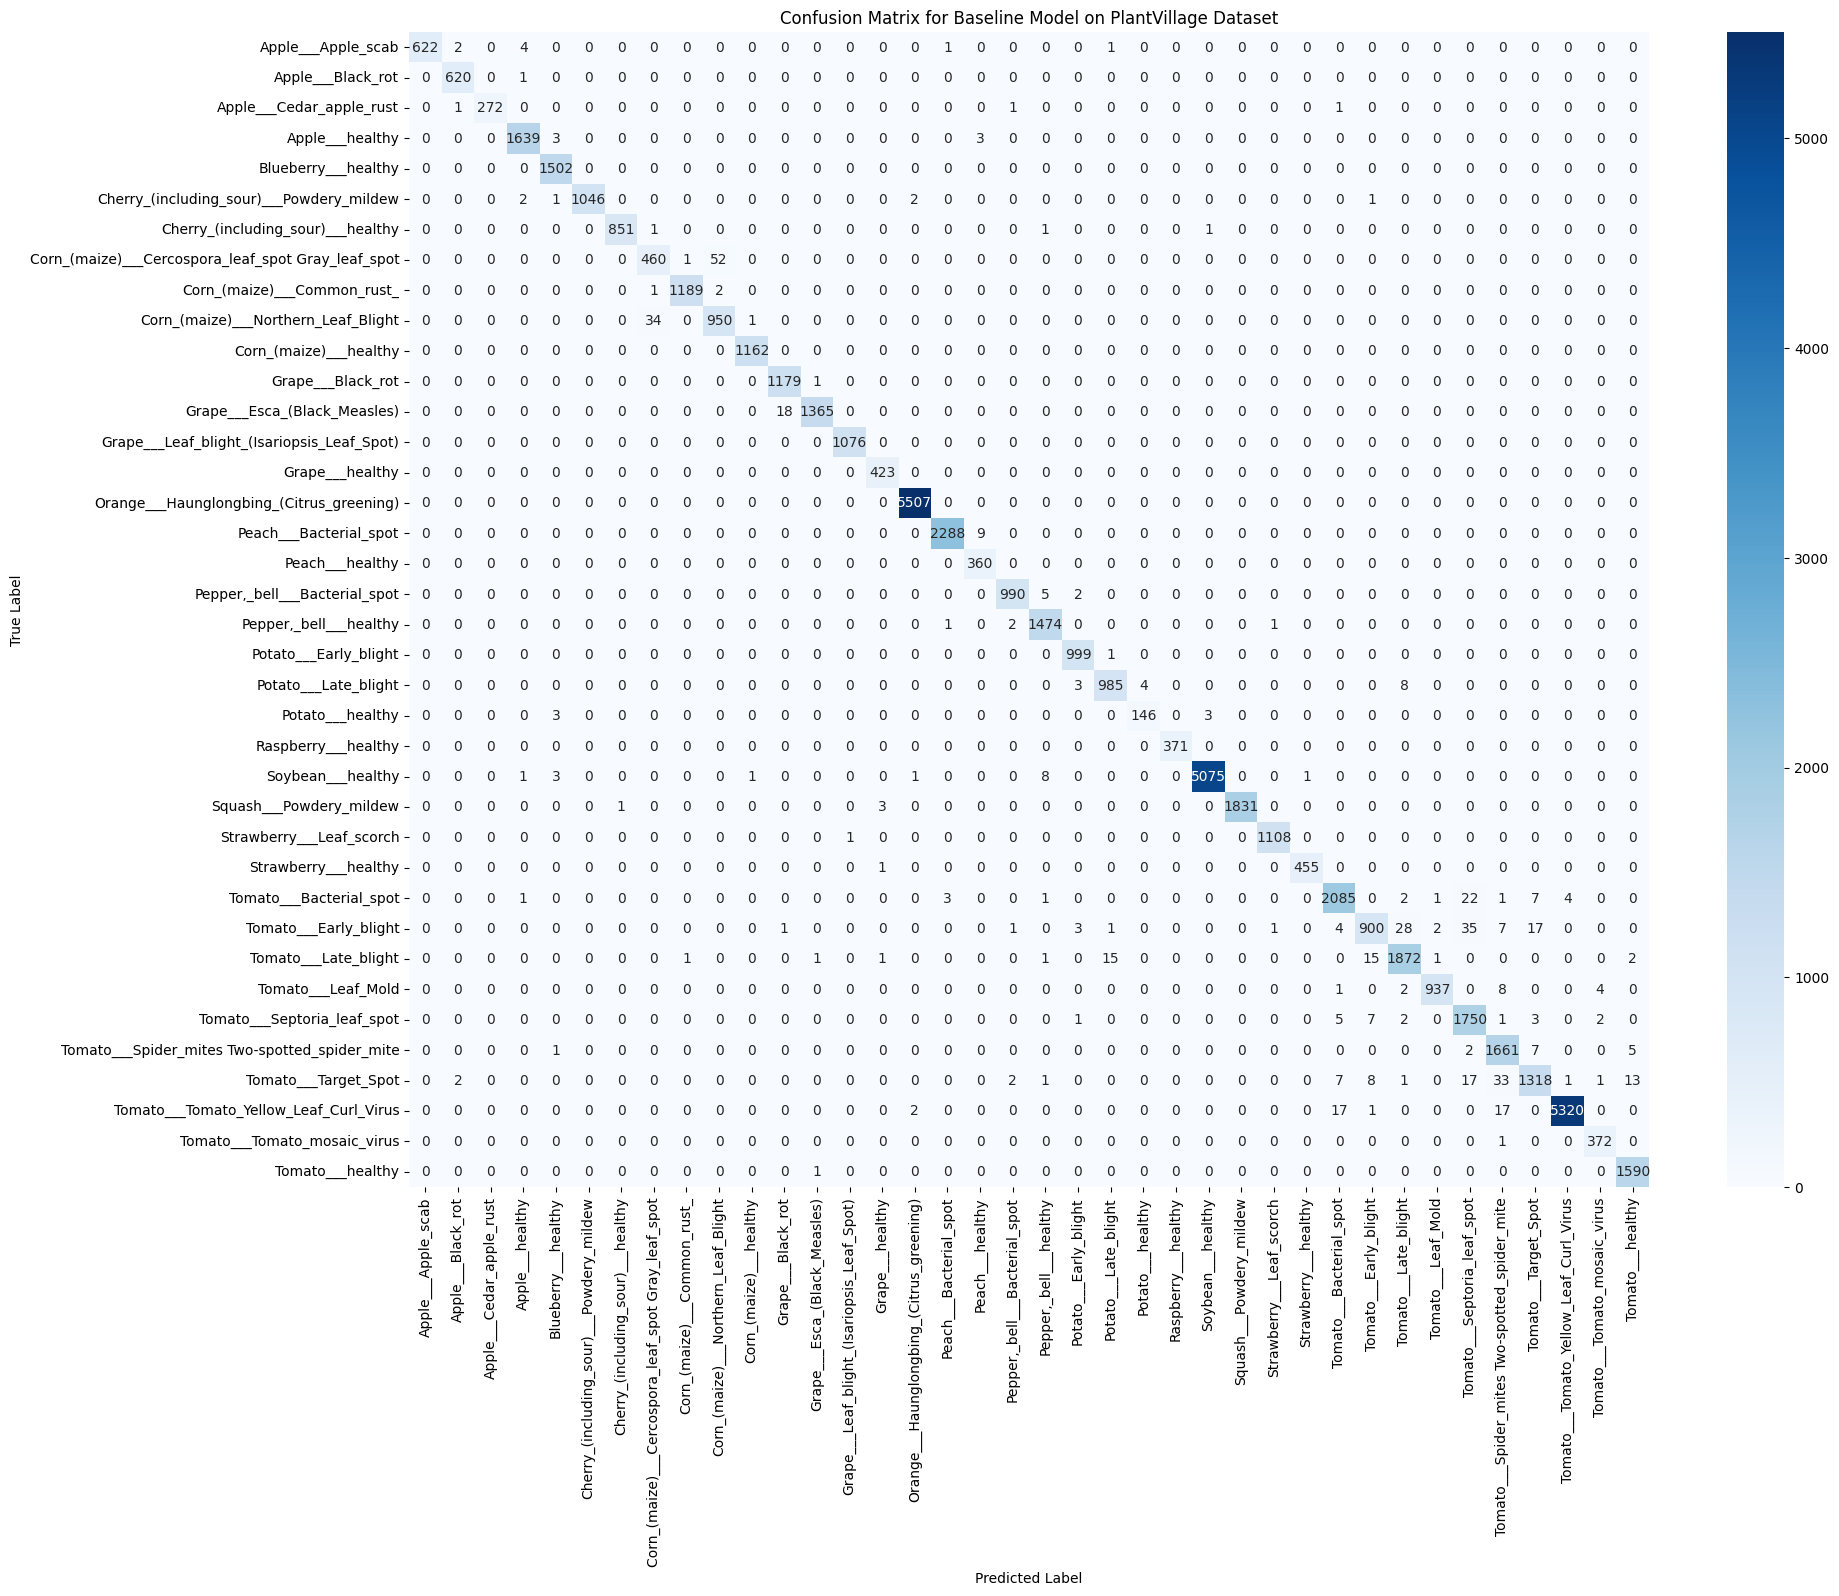

In [ ]:
# Generate Confusion Matrix
cm = confusion_matrix(true_labels, predictions)

plt.figure(figsize=(20, 15))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model_labels,
    yticklabels=model_labels
)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Baseline Model on PlantVillage Dataset')
plt.show()

### Class-Level Results of the Fine-Tuned Model on PlantVillage
Below we calculate and display the class-level performance metrics (Precision, Recall, and F1-score) for each of the 38 classes in the PlantVillage dataset.

In [ ]:
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support

# Calculate metrics per class
precision, recall, f1, support = precision_recall_fscore_support(
    true_labels,
    predictions,
    labels=range(len(model_labels)),
    zero_division=0
)

# Create a DataFrame to display results
class_performance_df = pd.DataFrame({
    "Class ID": range(len(model_labels)),
    "Class Name": model_labels,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Support": support
})

# Sort by F1-score to see which classes performed best/worst
class_performance_df = class_performance_df.sort_values("F1-score", ascending=False)

# Display the top 10 best-performing classes
print("--- Top 10 Best Performing Classes ---")
display(class_performance_df.head(10))

# Display the bottom 10 worst-performing classes
print("\n--- Bottom 10 Worst Performing Classes ---")
display(class_performance_df.tail(10))

--- Top 10 Best Performing Classes ---


,Class ID,Class Name,Precision,Recall,F1-score,Support
23,23,Raspberry___healthy,1.000000,1.000000,1.000000,371
15,15,Orange___Haunglongbing_(Citrus_greening),0.999093,1.000000,0.999546,5507
13,13,Grape___Leaf_blight_(Isariopsis_Leaf_Spot),0.999071,1.000000,0.999536,1076
10,10,Corn_(maize)___healthy,0.998282,1.000000,0.999140,1162
25,25,Squash___Powdery_mildew,1.000000,0.997820,0.998909,1835
26,26,Strawberry___Leaf_scorch,0.998198,0.999098,0.998648,1109
24,24,Soybean___healthy,0.999212,0.997053,0.998132,5090
8,8,Corn_(maize)___Common_rust_,0.998321,0.997483,0.997902,1192
27,27,Strawberry___healthy,0.997807,0.997807,0.997807,456
6,6,Cherry_(including_sour)___healthy,0.998826,0.996487,0.997655,854



--- Bottom 10 Worst Performing Classes ---


,Class ID,Class Name,Precision,Recall,F1-score,Support
21,21,Potato___Late_blight,0.982054,0.985000,0.983525,1000
28,28,Tomato___Bacterial_spot,0.983491,0.980254,0.981870,2127
30,30,Tomato___Late_blight,0.977546,0.980618,0.979079,1909
33,33,Tomato___Spider_mites Two-spotted_spider_mite,0.960671,0.991050,0.975624,1676
32,32,Tomato___Septoria_leaf_spot,0.958379,0.988142,0.973033,1771
22,22,Potato___healthy,0.973333,0.960526,0.966887,152
34,34,Tomato___Target_Spot,0.974852,0.938746,0.956459,1404
9,9,Corn_(maize)___Northern_Leaf_Blight,0.946215,0.964467,0.955254,985
29,29,Tomato___Early_blight,0.965665,0.900000,0.931677,1000
7,7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,0.927419,0.896686,0.911794,513
